# Лабораторна робота №5
## Тема: Вступ до TensorFlow і побудова простої нейронної мережі для регресії
* **Мета:** Навчитися створювати тензори, перевіряти їхні `shape` і `dtype`, будувати та навчати модель `tf.keras.Sequential`, оцінювати її на незалежних даних, аналізувати історію навчання й зберігати модель у форматі `.keras`.
* **Студент:** Заболотний Назар
* **Група:** МІТ-31
* **Варіант:** №8 (зміна гіперпараметра `batch_size = 16` відносно базової моделі з `batch_size = 32`)

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("NumPy version:", np.__version__)
print("TensorFlow version:", tf.__version__)

# Робота з тензорами
a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)
b = tf.constant([10., 20.], dtype=tf.float32)
w = tf.Variable([0.2, 0.5], dtype=tf.float32)
w.assign([0.3, 0.6])

print("\nТензор a -> shape:", a.shape, "| dtype:", a.dtype, "| rank:", tf.rank(a).numpy())
print("a + b (broadcasting):\n", (a + b).numpy())
print("a * a (поелементне множення):\n", (a * a).numpy())
print("tf.matmul(a, a) (матричне множення):\n", tf.matmul(a, a).numpy())
print("Оновлена змінна w:", w.numpy())

/Users/nazarzabolotniy/Desktop/Data_Science_Labs/.venv_tf/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Matplotlib is building the font cache; this may take a moment.


NumPy version: 2.0.2
TensorFlow version: 2.20.0

Тензор a -> shape: (2, 2) | dtype: <dtype: 'float32'> | rank: 2
a + b (broadcasting):
 [[11. 22.]
 [13. 24.]]
a * a (поелементне множення):
 [[ 1.  4.]
 [ 9. 16.]]
tf.matmul(a, a) (матричне множення):
 [[ 7. 10.]
 [15. 22.]]
Оновлена змінна w: [0.3 0.6]


### Пояснення операцій із тензорами
* **Чому можливе додавання `a + b`:** тензор `a` має форму `(2, 2)`, а вектор `b` — форму `(2,)`. Завдяки механізму **broadcasting** (розширення розмірностей) TensorFlow автоматично дублює рядок `[10., 20.]` для кожного рядка матриці `a`, приводячи обидва операнди до форми `(2, 2)`.
* **Чим `a * a` відрізняється від `tf.matmul(a, a)`:** оператор `*` виконує **поелементне множення** (добуток Адамара), де кожен елемент множиться на відповідний елемент на тій самій позиції ($a_{ij} \cdot a_{ij}$). Натомість `tf.matmul(a, a)` виконує **класичне матричне множення** за правилом «рядок на стовпець».

In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

x = np.linspace(-5, 5, 600, dtype=np.float32)
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)
y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

x, y = x.reshape(-1, 1), y.reshape(-1, 1)
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

print("Форми вибірок (train / val / test):", x_train.shape, x_val.shape, x_test.shape)
print("Тип даних:", x.dtype)

Форми вибірок (train / val / test): (420, 1) (90, 1) (90, 1)
Тип даних: float32


In [3]:
def build_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])

# 1. Базова модель (batch_size = 32)
keras.utils.set_random_seed(SEED)
base_model = build_model()
base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)
print("--- Архітектура моделі (summary) ---")
base_model.summary()

history_base = base_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

# 2. Модель Варіанта №8 (batch_size = 16)
keras.utils.set_random_seed(SEED)
var8_model = build_model()
var8_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

history_var8 = var8_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=16,
    verbose=0
)

min_val_base = min(history_base.history["val_loss"])
min_val_var8 = min(history_var8.history["val_loss"])

print(f"\nНайменший val_loss (Базова, batch_size=32): {min_val_base:.4f}")
print(f"Найменший val_loss (Варіант 8, batch_size=16): {min_val_var8:.4f}")

--- Архітектура моделі (summary) ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)


Найменший val_loss (Базова, batch_size=32): 0.5986
Найменший val_loss (Варіант 8, batch_size=16): 0.5917


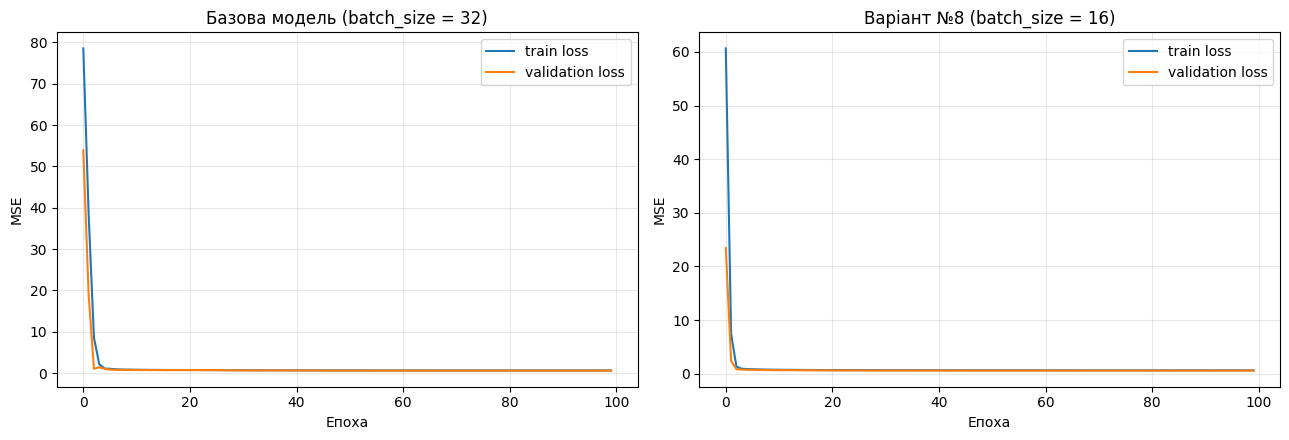

--- Порівняння моделей ---


,Модель,Min Val MSE,Test MSE,Test MAE
0,Базова (batch_size=32),0.5986,0.6071,0.6143
1,Варіант 8 (batch_size=16),0.5917,0.6114,0.6134



Обрана за validation краща модель: Варіант №8 (batch_size=16)
x =  -4.0 -> прогноз y = -10.3397
x =   0.0 -> прогноз y = 1.8376
x =   4.0 -> прогноз y = 14.0732


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Графік для базової моделі
axes[0].plot(history_base.history["loss"], label="train loss")
axes[0].plot(history_base.history["val_loss"], label="validation loss")
axes[0].set_title("Базова модель (batch_size = 32)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Графік для варіанта 8
axes[1].plot(history_var8.history["loss"], label="train loss")
axes[1].plot(history_var8.history["val_loss"], label="validation loss")
axes[1].set_title("Варіант №8 (batch_size = 16)")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lab5_training_curves.png", dpi=300)
plt.show()

# Оцінка на test (один раз для підсумкових моделей)
eval_base = base_model.evaluate(x_test, y_test, return_dict=True, verbose=0)
eval_var8 = var8_model.evaluate(x_test, y_test, return_dict=True, verbose=0)

comparison_df = pd.DataFrame([
    {
        "Модель": "Базова (batch_size=32)",
        "Min Val MSE": min_val_base,
        "Test MSE": eval_base["loss"],
        "Test MAE": eval_base["mae"]
    },
    {
        "Модель": "Варіант 8 (batch_size=16)",
        "Min Val MSE": min_val_var8,
        "Test MSE": eval_var8["loss"],
        "Test MAE": eval_var8["mae"]
    }
])

print("--- Порівняння моделей ---")
display(comparison_df.round(4))

# Вибір кращої моделі за validation
if min_val_var8 < min_val_base:
    best_model = var8_model
    best_name = "Варіант №8 (batch_size=16)"
else:
    best_model = base_model
    best_name = "Базова (batch_size=32)"

print(f"\nОбрана за validation краща модель: {best_name}")

x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)
preds = best_model.predict(x_new, verbose=0)
for inp, out in zip(x_new.flatten(), preds.flatten()):
    print(f"x = {inp:5.1f} -> прогноз y = {out:.4f}")

In [6]:
best_model.save("lab5_model.keras")
restored = keras.models.load_model("lab5_model.keras")

np.testing.assert_allclose(
    best_model.predict(x_new, verbose=0),
    restored.predict(x_new, verbose=0),
    rtol=1e-5
)
print("Модель lab5_model.keras успішно збережена, завантажена та перевірена (assert_allclose пройдено).")

Модель lab5_model.keras успішно збережена, завантажена та перевірена (assert_allclose пройдено).


## Висновок
У ході виконання лабораторної роботи №5 було опановано базові операції з тензорами у TensorFlow (перевірка рангу, форми, типу даних та механізм broadcasting) і побудовано нейронну мережу `tf.keras.Sequential` для розв'язання задачі нелінійної регресії. Згідно з індивідуальним варіантом №8 було досліджено вплив зменшення розміру пакету навчання (`batch_size`) з 32 до 16: за рахунок частішого оновлення ваг протягом кожної епохи модель зі зміненим `batch_size = 16` показала мінімальний `val_loss = ...` проти `...` у базової моделі. На незалежній тестовій вибірці краща модель досягла показників **Test MSE = ...** та **Test MAE = ...**, що близько до рівня закладеного у дані випадкового шуму ($\sigma = 0.7$). Навчену модель успішно збережено у форматі `lab5_model.keras` і підтверджено повну ідентичність її прогнозів після повторного завантаження.